# 02 · Comprensión de los datos (EDA)

**Fase 2 de CRISP-DM.** Objetivo: entender la composición del dataset, el desbalance de clases, qué tan
separables parecen las clases a partir del color, la diferencia entre las imágenes de Kaggle y las fotos
propias (cambio de dominio), la calidad del proxy de tamaño y la estructura de grupos que motivó el split
por grupos.

Todos los datos se cargan desde `data/splits.csv` (fuente única de verdad). Las figuras se guardan en
`docs/figures/` (gráficas en SVG vectorial para el informe; mosaicos de fotos en PNG).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageOps

from src.config import FRUITS, QUALITY_CLASSES, SPLITS, SEED
from src.data.carga import cargar_splits, cargar_imagen
from src.data.segmentacion import mascara_fruta, color_fondo

FIG_DIR = ROOT / "docs" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.bbox": "tight", "svg.fonttype": "none"})
COLORES = {"good": "#2a9d8f", "regular": "#e9b949", "bad": "#d1495b"}
FUENTE = {"kaggle": "#6c757d", "own": "#3a86ff"}

def guardar(fig, nombre):
    fig.savefig(FIG_DIR / nombre)
    print("guardada:", FIG_DIR.relative_to(ROOT) / nombre)

df = cargar_splits()
print(f"{len(df)} imágenes | columnas: {list(df.columns)}")
df.head()

5705 imágenes | columnas: ['filename', 'path', 'fruit', 'quality', 'source', 'split', 'grupo', 'tamano', 'area_ratio', 'diam_ratio', 'y']


,filename,path,fruit,quality,source,split,grupo,tamano,area_ratio,diam_ratio,y
0,apple_bad_own_00001.jpg,bad/apple_bad_own_00001.jpg,apple,bad,own,test_propias,g_apple_bad_own_00001,pequeno,0.5423,1.0,2
1,apple_bad_own_00002.jpg,bad/apple_bad_own_00002.jpg,apple,bad,own,test_propias,g_apple_bad_own_00002,mediano,0.6352,1.0,2
2,apple_bad_own_00003.jpg,bad/apple_bad_own_00003.jpg,apple,bad,own,test_propias,g_apple_bad_own_00003,mediano,0.6143,1.0,2
3,apple_bad_own_00004.jpg,bad/apple_bad_own_00004.jpg,apple,bad,own,test_propias,g_apple_bad_own_00004,pequeno,0.5864,1.0,2
4,apple_bad_own_00005.jpg,bad/apple_bad_own_00005.jpg,apple,bad,own,test_propias,g_apple_bad_own_00005,grande,0.8178,1.0,2


## 1. Composición y desbalance

Tres frutas × tres calidades. Kaggle aporta *good* y *bad*; la clase *regular* se construyó reetiquetando a
mano imágenes candidatas de Kaggle y con fotos propias.

In [2]:
tabla = (pd.crosstab([df.fruit, df.quality], df.split)
           .reindex(columns=SPLITS)
           .reindex(pd.MultiIndex.from_product([FRUITS, QUALITY_CLASSES])))
tabla["total"] = tabla.sum(axis=1)
tabla.loc[("TOTAL", ""), :] = tabla.sum()
tabla.astype(int)

split           train  val  test  test_propias  total
apple  good       752  159   167             6   1084
       regular     61   13    13             5     92
       bad        562  154   123             6    845
banana good       509  103   103             5    720
       regular     40    9     9             5     63
       bad        596  125   125             5    851
orange good       741  178   154             4   1077
       regular     45   10    10             5     70
       bad        578  166   154             5    903
TOTAL            3884  917   858            46   5705

In [3]:
por_clase = df.groupby("quality").size().reindex(QUALITY_CLASSES)
print("Proporción por clase (%):")
print((100 * por_clase / len(df)).round(2).to_string())
print(f"\nRazón de desbalance (mayoritaria / minoritaria): {por_clase.max() / por_clase.min():.1f} : 1")
print("Proporción de 'regular' por split (%):")
print((100 * df[df.quality == "regular"].groupby("split").size() / df.groupby("split").size())
      .reindex(SPLITS).round(1).to_string())

Proporción por clase (%):
quality
good       50.50
regular     3.94
bad        45.56

Razón de desbalance (mayoritaria / minoritaria): 12.8 : 1
Proporción de 'regular' por split (%):
split
train            3.8
val              3.5
test             3.7
test_propias    32.6


guardada: docs\figures\eda_distribucion_clases.svg


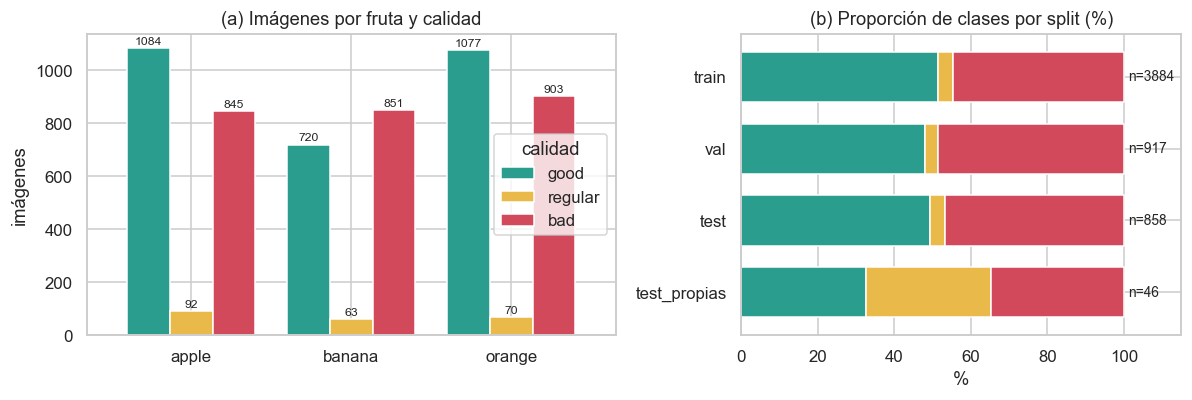

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1.2, 1]})

conteo = df.groupby(["fruit", "quality"]).size().unstack().reindex(index=FRUITS, columns=QUALITY_CLASSES)
conteo.plot.bar(ax=axes[0], color=[COLORES[q] for q in QUALITY_CLASSES], width=0.8, rot=0)
axes[0].set(title="(a) Imágenes por fruta y calidad", xlabel="", ylabel="imágenes")
for cont in axes[0].containers:
    axes[0].bar_label(cont, fontsize=8, padding=1)
axes[0].legend(title="calidad")

prop = (pd.crosstab(df.split, df.quality, normalize="index") * 100).reindex(index=SPLITS, columns=QUALITY_CLASSES)
prop.plot.barh(stacked=True, ax=axes[1], color=[COLORES[q] for q in QUALITY_CLASSES], width=0.7, legend=False)
axes[1].invert_yaxis()
axes[1].set(title="(b) Proporción de clases por split (%)", xlabel="%", ylabel="")
for i, s in enumerate(SPLITS):
    axes[1].text(101, i, f"n={int((df.split == s).sum())}", va="center", fontsize=9)
axes[1].set_xlim(0, 115)
fig.tight_layout()
guardar(fig, "eda_distribucion_clases.svg")
plt.show()

## 2. Ejemplos por clase

Cuatro imágenes de Kaggle y dos propias por cada combinación fruta–calidad (muestra aleatoria con semilla fija).

guardada: docs/figures/eda_ejemplos.png


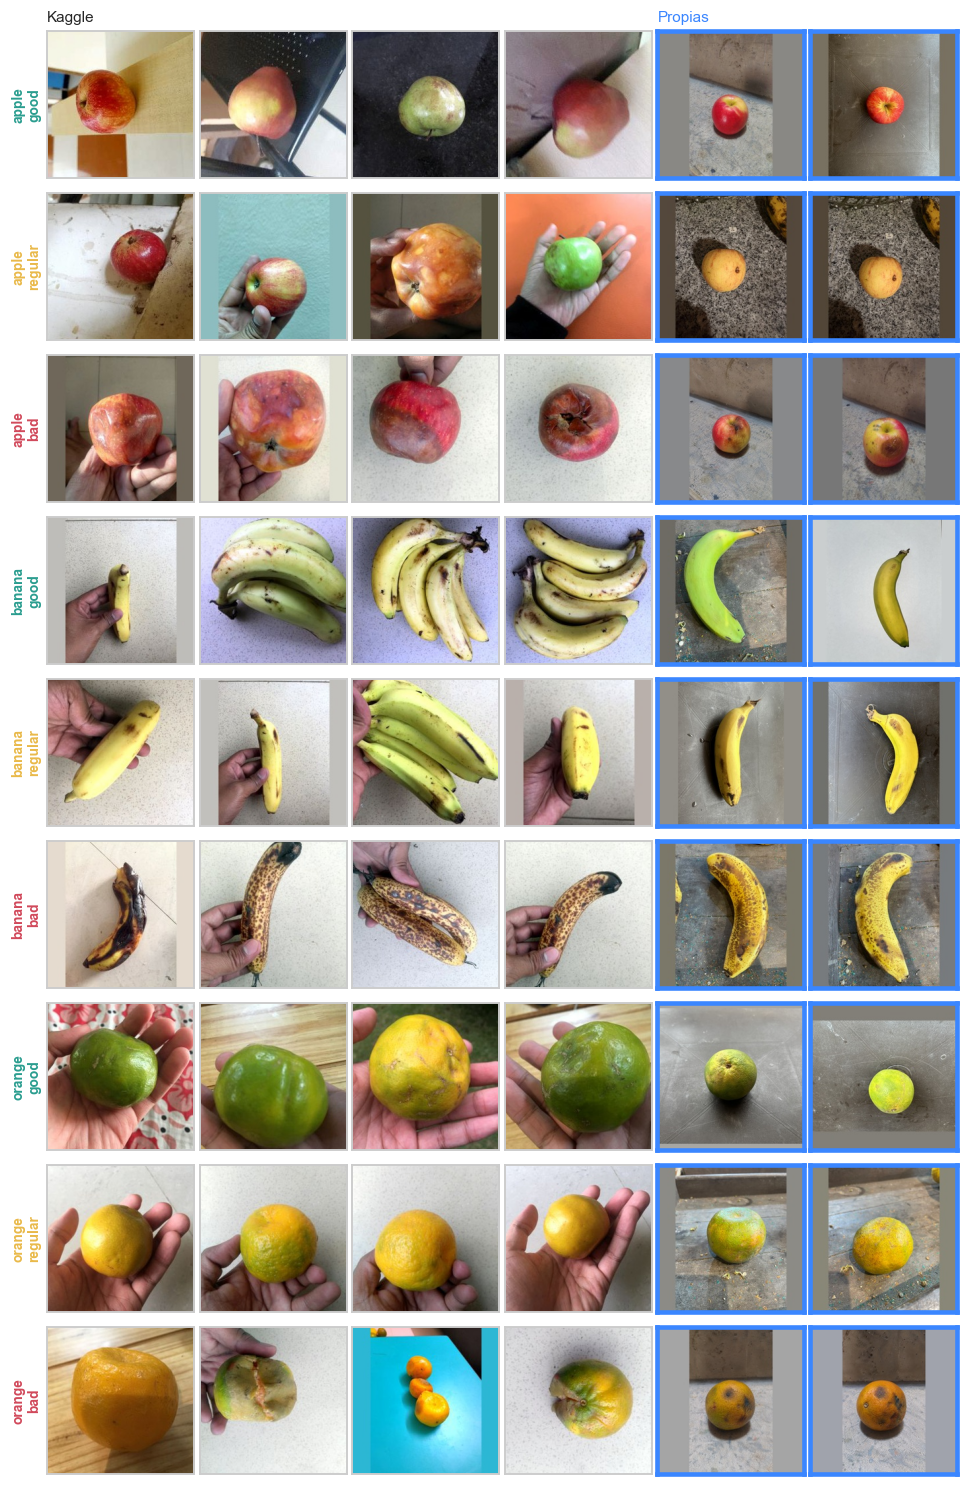

In [5]:
rng = np.random.default_rng(SEED)
n_kag, n_own = 4, 2
fig, axes = plt.subplots(9, n_kag + n_own, figsize=(1.45 * (n_kag + n_own), 1.5 * 9))
for r, (fruta, q) in enumerate([(f, q) for f in FRUITS for q in QUALITY_CLASSES]):
    sub = df[(df.fruit == fruta) & (df.quality == q)]
    kag = sub[sub.source == "kaggle"].sample(n_kag, random_state=SEED + r)
    own = sub[sub.source == "own"].sample(min(n_own, (sub.source == "own").sum()), random_state=SEED + r)
    for c, (_, fila) in enumerate(pd.concat([kag, own]).iterrows()):
        ax = axes[r, c]
        ax.imshow(cargar_imagen(fila))
        if fila.source == "own":
            for s in ax.spines.values():
                s.set_edgecolor(FUENTE["own"]); s.set_linewidth(3)
    for ax in axes[r]:
        ax.set_xticks([]); ax.set_yticks([])
    axes[r, 0].set_ylabel(f"{fruta}\n{q}", fontsize=9, color=COLORES[q], fontweight="bold")
axes[0, 0].set_title("Kaggle", loc="left", fontsize=10)
axes[0, n_kag].set_title("Propias", loc="left", fontsize=10, color=FUENTE["own"])
fig.tight_layout(pad=0.3)
fig.savefig(FIG_DIR / "eda_ejemplos.png", dpi=150)
print("guardada: docs/figures/eda_ejemplos.png")
plt.show()

## 3. Descriptores de color por imagen

Para cada imagen se separa la fruta del fondo con `src/data/segmentacion.py` (distancia RGB al color mediano
del borde > 40) y se calculan, **sobre los píxeles de la fruta**, descriptores en el espacio HSV:

| descriptor | definición | intuición |
|---|---|---|
| `V_media` | brillo medio (V ∈ [0,1]) | la podredumbre oscurece |
| `S_media` | saturación media | frutas sanas tienen color más vivo |
| `H_media` | tono medio (media circular, grados) | verde → amarillo/naranja → rojo |
| `frac_oscura` | fracción de píxeles con V < 0,35 | proxy de manchas y podredumbre |
| `area_proc` | fracción de la imagen procesada ocupada por la fruta | tamaño relativo |

Además, para medir el **cambio de dominio**, se calcula la desviación estándar del color del borde
(`fondo_std`: qué tan uniforme es el fondo) y el brillo global de la imagen.

In [6]:
def descriptores(fila):
    img = cargar_imagen(fila)
    rgb = np.asarray(img, dtype=np.float32)
    hsv = np.asarray(img.convert("HSV"), dtype=np.float32) / 255.0
    m = mascara_fruta(rgb)
    if m.sum() < 50:                 # segmentación fallida: se usa toda la imagen
        m = np.ones(m.shape, bool)
    h, s, v = hsv[..., 0][m], hsv[..., 1][m], hsv[..., 2][m]
    ang = 2 * np.pi * h
    h_media = (np.degrees(np.arctan2(np.sin(ang).mean(), np.cos(ang).mean())) + 360) % 360
    b = max(2, int(0.05 * rgb.shape[0]))
    borde = np.concatenate([rgb[:b].reshape(-1, 3), rgb[-b:].reshape(-1, 3),
                            rgb[:, :b].reshape(-1, 3), rgb[:, -b:].reshape(-1, 3)])
    return {"V_media": v.mean(), "S_media": s.mean(), "H_media": h_media,
            "frac_oscura": (v < 0.35).mean(), "area_proc": m.mean(),
            "fondo_std": borde.std(axis=0).mean() / 255.0,
            "brillo_global": hsv[..., 2].mean()}

desc = pd.DataFrame([descriptores(f) for _, f in df.iterrows()])
dfd = pd.concat([df, desc], axis=1)
dfd.groupby(["fruit", "quality"])[["V_media", "S_media", "H_media", "frac_oscura"]].median() \
   .reindex(pd.MultiIndex.from_product([FRUITS, QUALITY_CLASSES])).round(3)

V_media  S_media    H_media  frac_oscura
apple  good       0.582    0.357  47.842999        0.170
       regular    0.564    0.342  29.947001        0.207
       bad        0.646    0.331  33.265999        0.111
banana good       0.686    0.307  47.257000        0.109
       regular    0.685    0.257  35.973999        0.109
       bad        0.628    0.265  42.515999        0.134
orange good       0.605    0.400  54.907001        0.178
       regular    0.639    0.382  36.570999        0.139
       bad        0.676    0.388  37.312000        0.095

guardada: docs\figures\eda_color_por_calidad.svg


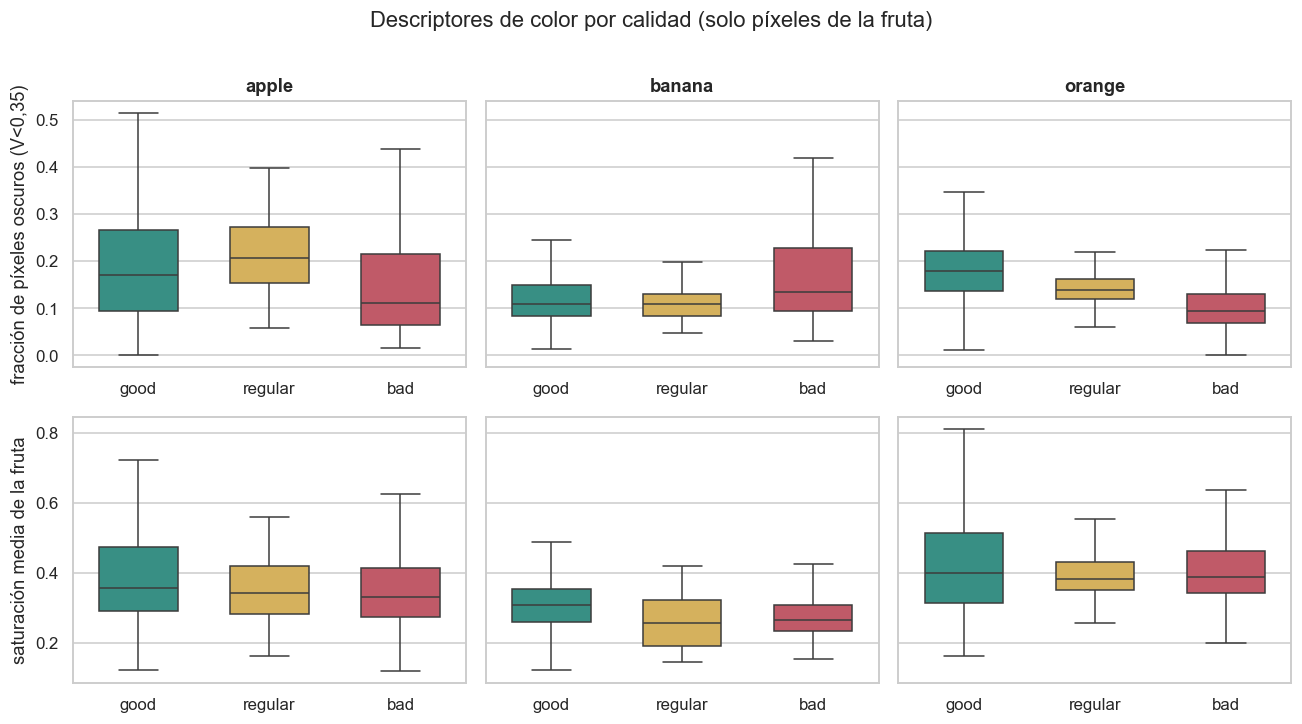

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6.5), sharey="row")
for c, fruta in enumerate(FRUITS):
    sub = dfd[dfd.fruit == fruta]
    for r, (col, nombre) in enumerate([("frac_oscura", "fracción de píxeles oscuros (V<0,35)"),
                                       ("S_media", "saturación media de la fruta")]):
        ax = axes[r, c]
        sns.boxplot(data=sub, x="quality", y=col, hue="quality", order=QUALITY_CLASSES,
                    palette=COLORES, ax=ax, showfliers=False, width=0.6, legend=False)
        ax.set(xlabel="", ylabel=nombre if c == 0 else "")
        if r == 0:
            ax.set_title(fruta, fontweight="bold")
fig.suptitle("Descriptores de color por calidad (solo píxeles de la fruta)", y=1.01)
fig.tight_layout()
guardar(fig, "eda_color_por_calidad.svg")
plt.show()

**¿Qué tan separables son las clases con un solo descriptor?** Como referencia rápida se calcula, para cada
descriptor y fruta, el AUC de *bad vs good* y de *regular vs resto*, y el tamaño de efecto. Un AUC de 0,5
equivale a azar; cerca de 1 (o de 0) indica buena separación.

In [8]:
from sklearn.metrics import roc_auc_score

filas = []
for fruta in FRUITS:
    sub = dfd[dfd.fruit == fruta]
    for col in ["V_media", "S_media", "H_media", "frac_oscura"]:
        gb = sub[sub.quality.isin(["good", "bad"])]
        auc_gb = roc_auc_score(gb.quality == "bad", gb[col])
        auc_reg = roc_auc_score(sub.quality == "regular", sub[col])
        filas.append({"fruta": fruta, "descriptor": col,
                      "AUC bad vs good": max(auc_gb, 1 - auc_gb),
                      "AUC regular vs resto": max(auc_reg, 1 - auc_reg)})
auc = pd.DataFrame(filas).pivot(index="descriptor", columns="fruta")
auc.round(2)

AUC bad vs good               AUC regular vs resto              
fruta                 apple banana orange                apple banana orange
descriptor                                                                  
H_media                0.64   0.57   0.65                 0.66   0.61   0.68
S_media                0.57   0.64   0.50                 0.52   0.62   0.52
V_media                0.63   0.77   0.76                 0.66   0.64   0.51
frac_oscura            0.61   0.60   0.81                 0.65   0.58   0.52

## 4. Cambio de dominio: Kaggle vs fotos propias

Las fotos propias son el conjunto de prueba externo (`test_propias`). Si su distribución difiere de la de
Kaggle, es esperable que el rendimiento baje allí.

guardada: docs\figures\eda_dominio_kaggle_vs_propias.svg


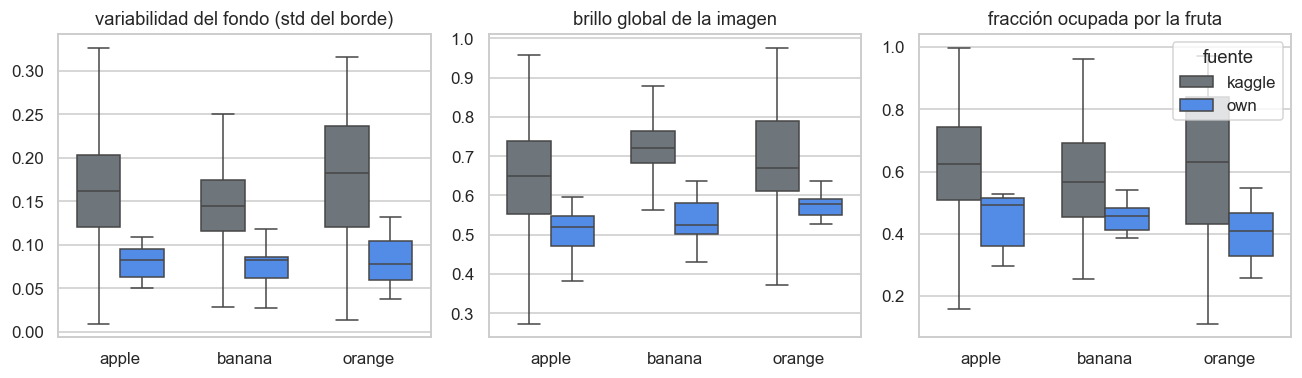

,fondo_std,brillo_global,area_proc,V_media,S_media
source,,,,,
kaggle,0.160,0.692,0.599,0.636,0.341
own,0.082,0.541,0.452,0.542,0.299


In [9]:
cols = [("fondo_std", "variabilidad del fondo (std del borde)"),
        ("brillo_global", "brillo global de la imagen"),
        ("area_proc", "fracción ocupada por la fruta")]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, (col, nombre) in zip(axes, cols):
    sns.boxplot(data=dfd, x="fruit", y=col, hue="source", order=FRUITS, hue_order=["kaggle", "own"],
                palette=FUENTE, ax=ax, showfliers=False, width=0.7)
    ax.set(title=nombre, xlabel="", ylabel="")
    if ax is not axes[-1]:
        ax.get_legend().remove()
axes[-1].legend(title="fuente", loc="upper right")
fig.tight_layout()
guardar(fig, "eda_dominio_kaggle_vs_propias.svg")
plt.show()

resumen = dfd.groupby("source")[[c for c, _ in cols] + ["V_media", "S_media"]].median().round(3)
resumen

### 4.1 ¿El fondo delata la clase? (prueba de "atajo")

En los ejemplos se ve que en Kaggle muchas fotos de una misma clase comparten superficie (p. ej. *bad*
sobre una encimera beige moteada). Si el fondo predice la calidad, un modelo puede aprender el fondo en
lugar de la fruta y fallar con fotos nuevas. Para medirlo se entrena un Random Forest que **solo ve el
borde de la imagen** (franja del 8 % del lado: mediana, desviación y percentiles RGB y HSV del borde) y se
evalúa con validación cruzada por grupos dentro de `train`. Si su macro-F1 supera claramente al azar, el
atajo existe.

In [10]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.metrics import f1_score, classification_report

def descriptores_borde(fila, frac=0.08):
    img = cargar_imagen(fila)
    feats = []
    for arr in (np.asarray(img, np.float32) / 255, np.asarray(img.convert("HSV"), np.float32) / 255):
        b = max(2, int(frac * arr.shape[0]))
        borde = np.concatenate([arr[:b].reshape(-1, 3), arr[-b:].reshape(-1, 3),
                                arr[:, :b].reshape(-1, 3), arr[:, -b:].reshape(-1, 3)])
        feats += list(np.median(borde, 0)) + list(borde.std(0)) + \
                 list(np.percentile(borde, 10, 0)) + list(np.percentile(borde, 90, 0))
    return feats

tr = df[df.split == "train"].reset_index(drop=True)
Xb = np.array([descriptores_borde(f) for _, f in tr.iterrows()])
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
rf = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=SEED, n_jobs=-1)
pred = cross_val_predict(rf, Xb, tr.y, groups=tr.grupo, cv=cv)

f1_borde = f1_score(tr.y, pred, average="macro")
azar = f1_score(tr.y, np.random.default_rng(SEED).permutation(tr.y.values), average="macro")
print(f"macro-F1 usando SOLO el fondo: {f1_borde:.3f}   (etiquetas barajadas: {azar:.3f})")
print(classification_report(tr.y, pred, target_names=QUALITY_CLASSES, digits=3))

macro-F1 usando SOLO el fondo: 0.620   (etiquetas barajadas: 0.331)
              precision    recall  f1-score   support

        good      0.851     0.935     0.891      2002
     regular      0.353     0.041     0.074       146
         bad      0.914     0.878     0.896      1736

    accuracy                          0.876      3884
   macro avg      0.706     0.618     0.620      3884
weighted avg      0.861     0.876     0.863      3884



## 5. Tamaño

`area_ratio` (en `splits.csv`) es la fracción de la **foto original** ocupada por la fruta, calculada en
`prepare_dataset.py`. Es un proxy del tamaño, válido solo si la distancia cámara–fruta es similar entre
fotos. `tamano` son los terciles de `area_ratio` por fruta, con cortes calculados solo en `train`.
`diam_ratio` (lado mayor del bounding box / lado mayor de la imagen) se revisa también.

guardada: docs\figures\eda_tamano.svg


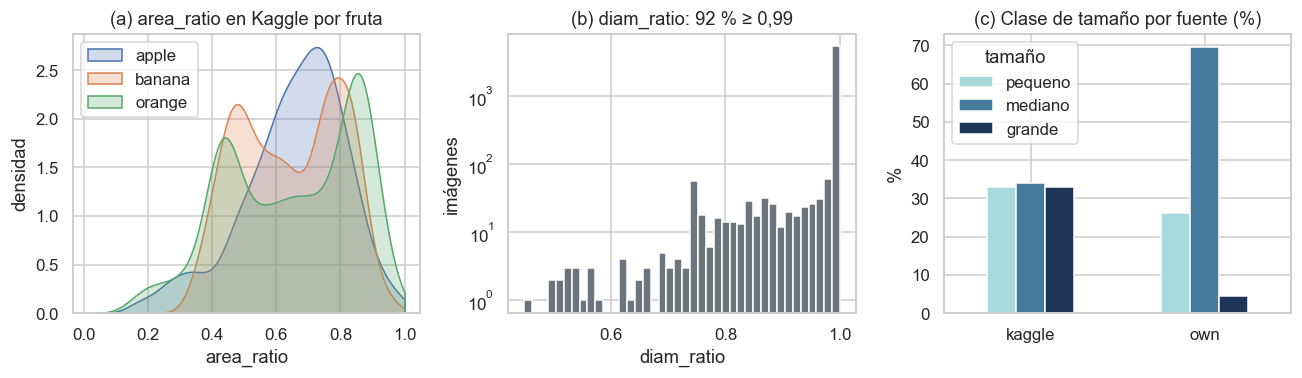

Correlación de Spearman area_ratio (original) vs area_proc (procesada): 0.919


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for fruta in FRUITS:
    sns.kdeplot(dfd[(dfd.fruit == fruta) & (dfd.source == "kaggle")].area_ratio, ax=axes[0],
                label=fruta, fill=True, alpha=0.25, clip=(0, 1))
axes[0].set(title="(a) area_ratio en Kaggle por fruta", xlabel="area_ratio", ylabel="densidad")
axes[0].legend()

axes[1].hist(dfd.diam_ratio, bins=40, color="#6c757d")
axes[1].set(title=f"(b) diam_ratio: {100 * (dfd.diam_ratio >= 0.99).mean():.0f} % ≥ 0,99",
            xlabel="diam_ratio", ylabel="imágenes")
axes[1].set_yscale("log")

orden_t = ["pequeno", "mediano", "grande"]
pt = (pd.crosstab(dfd.source, dfd.tamano, normalize="index") * 100).reindex(columns=orden_t)
pt.plot.bar(ax=axes[2], rot=0, color=["#a8dadc", "#457b9d", "#1d3557"])
axes[2].set(title="(c) Clase de tamaño por fuente (%)", xlabel="", ylabel="%")
axes[2].legend(title="tamaño")
fig.tight_layout()
guardar(fig, "eda_tamano.svg")
plt.show()

print("Correlación de Spearman area_ratio (original) vs area_proc (procesada):",
      round(dfd[["area_ratio", "area_proc"]].corr(method="spearman").iloc[0, 1], 3))

## 6. Grupos de la misma toma y fuga de información

Kaggle contiene ráfagas: varias fotos de la misma fruta tomadas con 1–2 s de diferencia. `make_splits.py`
agrupa esas tomas (dHash ≤ 20 o ráfaga consecutiva) y asigna cada grupo a un único split. Aquí se cuantifica
el efecto comparando con un split **por imagen** (estratificado, misma semilla y proporciones), que es lo
que se habría obtenido sin agrupar.

In [12]:
def dhash(img):
    px = np.asarray(img.convert("L").resize((17, 16)), dtype=int)
    return (px[:, 1:] > px[:, :-1]).flatten()

imgs = [cargar_imagen(f) for _, f in df.iterrows()]
H = np.array([dhash(i) for i in imgs])
M = np.array([dhash(ImageOps.mirror(i)) for i in imgs])
del imgs

pares_i, pares_j, pares_d = [], [], []
for i in range(len(df) - 1):
    d = np.minimum((H[i] != H[i + 1:]).sum(1), (H[i] != M[i + 1:]).sum(1))
    k = np.where(d <= 30)[0]
    pares_i += [i] * len(k); pares_j += list(i + 1 + k); pares_d += list(d[k])
pares = pd.DataFrame({"i": pares_i, "j": pares_j, "d": pares_d})
print(f"Parejas con dHash <= 30: {len(pares)}")

Parejas con dHash <= 30: 4248


In [13]:
from sklearn.model_selection import train_test_split

# Split por imagen equivalente (sin grupos), solo para comparar
kag = df[df.source == "kaggle"]
estr = kag.fruit + "_" + kag.quality
tr, resto = train_test_split(kag.index, train_size=0.70, stratify=estr, random_state=SEED)
va, te = train_test_split(resto, test_size=0.5, stratify=estr.loc[resto], random_state=SEED)
split_img = df.split.copy()
split_img.loc[tr], split_img.loc[va], split_img.loc[te] = "train", "val", "test"

filas = []
for nombre, sp in [("por imagen", split_img.values), ("por grupos (actual)", df.split.values)]:
    for umbral in (10, 20, 30):
        p = pares[pares.d <= umbral]
        filas.append({"split": nombre, "umbral dHash": umbral,
                      "parejas en splits distintos": int((sp[p.i] != sp[p.j]).sum()),
                      "con test": int(((sp[p.i] != sp[p.j]) & ((sp[p.i] == "test") | (sp[p.j] == "test"))).sum())})
fuga = pd.DataFrame(filas)
fuga.pivot(index="umbral dHash", columns="split", values="parejas en splits distintos")

split,por grupos (actual),por imagen
umbral dHash,,
10,0,1
20,0,1017
30,57,2060


guardada: docs\figures\eda_grupos_fuga.svg


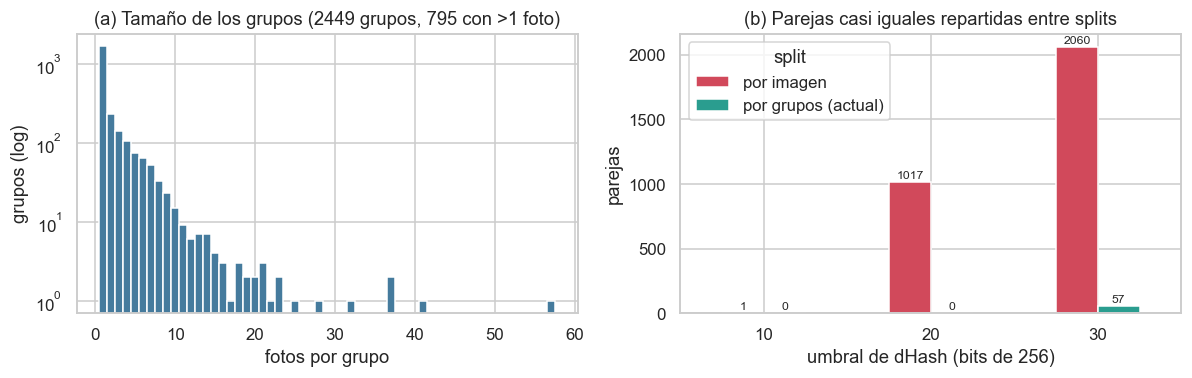

Grupos independientes con alguna 'regular' de Kaggle: {'apple': 78, 'banana': 25, 'orange': 49} | imágenes: 210


In [14]:
tam = df.groupby("grupo").size()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
bins = np.arange(1, tam.max() + 2) - 0.5
axes[0].hist(tam, bins=bins, color="#457b9d")
axes[0].set_yscale("log")
axes[0].set(title=f"(a) Tamaño de los grupos ({len(tam)} grupos, {(tam > 1).sum()} con >1 foto)",
            xlabel="fotos por grupo", ylabel="grupos (log)")

piv = fuga.pivot(index="umbral dHash", columns="split", values="parejas en splits distintos")
piv[["por imagen", "por grupos (actual)"]].plot.bar(ax=axes[1], rot=0, color=["#d1495b", "#2a9d8f"])
for cont in axes[1].containers:
    axes[1].bar_label(cont, fontsize=8, padding=1)
axes[1].set(title="(b) Parejas casi iguales repartidas entre splits", xlabel="umbral de dHash (bits de 256)",
            ylabel="parejas")
fig.tight_layout()
guardar(fig, "eda_grupos_fuga.svg")
plt.show()

reg = df[(df.quality == "regular") & (df.source == "kaggle")]
print("Grupos independientes con alguna 'regular' de Kaggle:", reg.groupby("fruit").grupo.nunique().to_dict(),
      "| imágenes:", len(reg))

## 7. Conclusiones del EDA

1. **Desbalance fuerte.** *good* 50,5 %, *bad* 45,6 %, *regular* 3,9 % (razón 12,8:1). La proporción de
   *regular* es estable en train/val/test (3,5–3,8 %), pero es de 32,6 % en `test_propias`. Accuracy no sirve
   como métrica principal: se usará **macro-F1** y recall por clase, con pesos de clase o sobremuestreo de
   *regular* solo en train.
2. **"regular" es la clase difícil y pequeña.** Las 210 imágenes de Kaggle vienen de solo 78/25/49 grupos
   independientes (manzana/banano/naranja), y en test hay 9–13 por fruta: sus métricas tendrán mucha varianza.
3. **El fondo es un atajo (shortcut) en Kaggle.** Un Random Forest que solo ve el borde de la imagen logra
   macro-F1 = 0,62 y F1 ≈ 0,89 en *good* y *bad* (azar: 0,33). Muchas fotos de una misma clase comparten
   superficie. Un modelo entrenado sobre la imagen completa puede aprender el fondo y no la fruta, y fallar con
   fotos nuevas. **Consecuencias para el modelado:** (a) calcular las características manuales solo sobre la
   fruta; (b) para la CNN, aumento de datos fuerte de color y recorte, y probar enmascarar o recortar el fondo;
   (c) `test_propias`, con fondos distintos, es la prueba real de generalización. (Matiz: en Kaggle la fruta y
   la mano a veces tocan el borde, así que la franja no es fondo puro.)
4. **Manos y fondos variados contaminan la segmentación simple.** En Kaggle la fruta suele estar en la mano y
   los fondos no son uniformes, así que la máscara por distancia al color del borde incluye manos y partes de
   fondo. Por eso algunos descriptores dan resultados contraintuitivos (p. ej. manzana *bad* con mayor brillo
   medio que *good*). Hace falta una segmentación más robusta (umbral en HSV/Otsu + componente conexa
   principal, o descartar tonos de piel) antes de extraer características.
5. **El color separa poco por sí solo.** Con un único descriptor, el AUC *bad vs good* está entre 0,50 y 0,81
   (el mejor es la fracción de píxeles oscuros en naranja, 0,81), y para *regular vs resto* entre 0,51 y 0,68.
   Hace falta combinar color, textura y forma (ML clásico) o aprender características (CNN).
6. **Cambio de dominio Kaggle → fotos propias.** Las fotos propias son más oscuras (brillo 0,54 vs 0,69), la
   fruta ocupa menos de la imagen (0,45 vs 0,60) y el fondo es más uniforme (fondo en el suelo, sin mano). Se
   espera una caída de rendimiento en `test_propias`; reportarla es parte del análisis de generalización.
7. **Tamaño.** `diam_ratio` es inútil (≈1 en casi todas las imágenes). `area_ratio` es un proxy razonable
   dentro de una misma fuente (Spearman 0,92 con el área medida en la imagen procesada), pero no es tamaño
   real: en Kaggle depende de qué tan cerca se tomó la foto, y en las propias se concentra en "mediano".
8. **El split por grupos elimina la fuga.** Un split por imagen habría dejado 1.017 parejas casi idénticas
   (dHash ≤ 20) repartidas entre splits; con el split por grupos quedan 0 (y 57 con dHash 21–30).